

This simple example shows how to use the Dask dataframes API to execute a simple query on the main source catalogue and plot the results.

Notes:

* The cell containing the query below finishes instantly since it merely defines an operations which is then 'lazily' evaluated when required. It is only when something is done with the data selected by this transform (i.e. it is explicitly actioned as in the following cell) that execution occurs
* Visualisation takes advantage of HEALPix pixelisation encoded in the Gaia source IDs, and the healpy Python package in conjunction with matplotlib



In [ ]:
# Do the imports
from dask.distributed import Client
import dask.dataframe as dd
import seaborn as sns
import time
import dask
import numpy as np
import healpy as hp
import matplotlib.pyplot as plot
import math
import os
from pathlib import Path

# Set up the client
c = Client('tcp://simple-scheduler.dask-operator.svc.cluster.local:8786')
print(c)

<Client: 'tcp://192.168.63.173:8786' processes=10 threads=60, memory=250.00 GiB>


/usr/local/lib/python3.10/site-packages/distributed/client.py:1612: VersionMismatchWarning: Mismatched versions found

+---------+-----------------+-----------------+-----------------+
| Package | Client          | Scheduler       | Workers         |
+---------+-----------------+-----------------+-----------------+
| lz4     | 4.4.4           | 4.3.3           | 4.3.3           |
| numpy   | 2.2.6           | 2.2.2           | 2.2.2           |
| python  | 3.10.16.final.0 | 3.10.12.final.0 | 3.10.12.final.0 |
| toolz   | 1.0.0           | 0.12.0          | 0.12.0          |
| tornado | 6.4.1           | 6.4.2           | 6.4.2           |
+---------+-----------------+-----------------+-----------------+
  warnings.warn(version_module.VersionMismatchWarning(msg[0]["warning"]))


In [ ]:
healpix_level = 6
nside = int(math.pow(2, healpix_level))
powers_of_2 = 35 + (12 - healpix_level)*2
divisor = int(math.pow(2, powers_of_2))
ddf = dd.read_parquet(Path(os.environ['DASK_DATA_PATH_GAIA_DR3_SSD']).joinpath('GDR3_GAIA_SOURCE/'), columns=["source_id"])

/usr/local/lib/python3.10/site-packages/healpy/visufunc.py:200: UserWarning: Ignoring specified arguments in this call because figure with num: 1 already exists
  f = pylab.figure(fig, figsize=(8.5, 5.4))


time: 26.459335327148438


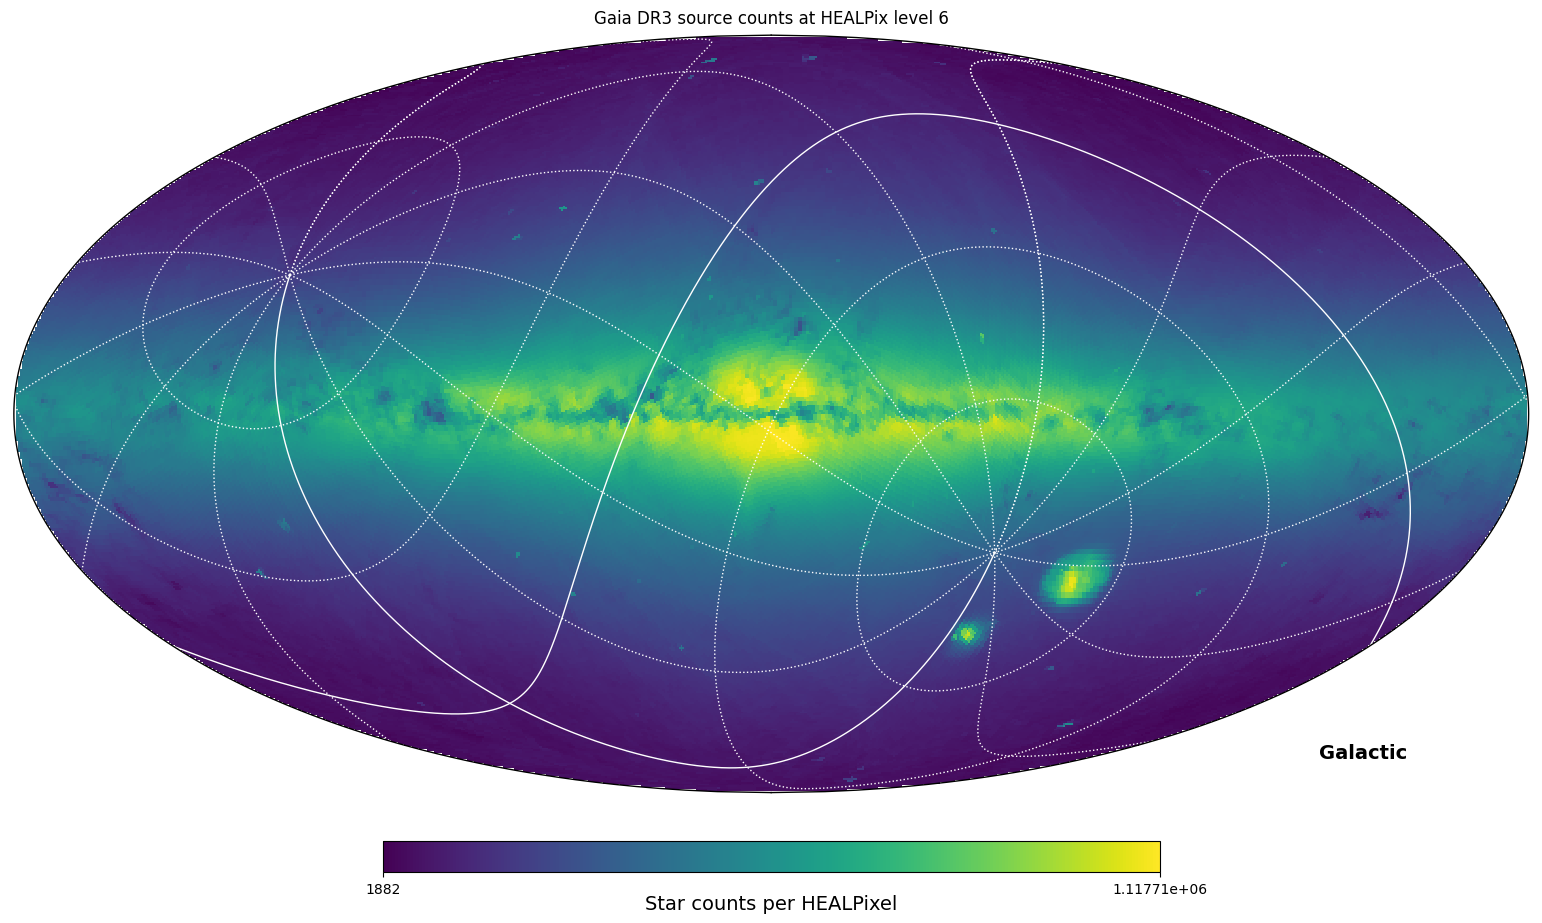

In [3]:
start_time = time.time()

# This is using the dataframe approach not the SparkSQL approach
ddf["hpx_id"] = np.floor(ddf.source_id / divisor)
result_df = ddf.groupby("hpx_id").hpx_id.count() #.rename(columns={"count": "n"})
results = [result_df, ]
r = dask.compute(*results)

# set a figure to use along with a plot size (landscape, golden ratio)
plot.figure(1, figsize = (16.18, 10.0))

# healpy constants appropriate to the HEALPix indexing encoded in Gaia source IDs
npix = hp.nside2npix(nside)

# do the visualisation
array_data = np.empty(npix)
    
for i, v in r[0].items():
    array_data[int(i)] = v

# plot the counts in Mollweide projection ...
hp.mollview(array_data, fig=1, nest=True, coord='CG', unit = 'Star counts per HEALPixel', title='Gaia DR3 source counts at HEALPix level %d'%(healpix_level), cmap='viridis', norm = 'log')
# ... with an Equatorial graticule
hp.graticule(coord='C', color='white')

end_time = time.time()
print(f'time: {end_time - start_time}')